# MECHA, 5: experimental data

**What you will learn:** give the model measured inputs (each root's anatomy), compare its outputs with observed
conductivities, measure the difference, and fit a parameter so that the model matches the observations.

**You need:** tutorials 1 and 2, and a little pandas. **Run time:** about 30 seconds.

**About the data.** The files in `data/` are **synthetic**: `data/make_synthetic_data.py` made them from the model
itself, with a known value of the aquaporin parameter `kaqp` and some random noise. They stand for what an
experiment gives. Since the true value is known, we can check that the fit finds it. Your own measurements go in
files of the same form.

## 1. The data

- `measured_roots.csv`: five roots of one plant, the number of **cortex cell layers** of each, as counted on
  microscope images of their cross sections;
- `observed_kr.csv`: the **radial conductivity** of each root, as a root pressure probe or a pressure chamber would
  measure it, in m s⁻¹ MPa⁻¹ (the unit of most publications).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.mecha.simulation import simulate

roots = pd.read_csv("data/measured_roots.csv")
observed = pd.read_csv("data/observed_kr.csv")
data = roots.merge(observed, on="root")
data

,root,cortex_layers,kr
0,R1,3,2.450000e-07
1,R2,4,2.020000e-07
2,R3,5,1.850000e-07
3,R4,6,1.550000e-07
4,R5,8,1.170000e-07


The observations are in m s⁻¹ MPa⁻¹: the summary's `kr_SI` is in the same unit. With MECHA's own unit
(cm hPa⁻¹ d⁻¹), multiply by 1/864 to convert.

## 2. Measured inputs: each root's anatomy

Each root is simulated with its own measured number of cortex layers, through GRANAP's anatomy parameters:

In [2]:
def simulate_roots(parameters=None):
    """kr (m s-1 MPa-1) of each measured root, with MECHA's *parameters*."""
    return np.array([simulate(parameters, anatomy={"cortex": {"n_layers": int(layers)}}).summary["kr_SI"]
                     for layers in data["cortex_layers"]])


with_defaults = simulate_roots()

## 3. Compare with the observations

error with the defaults: 28 %


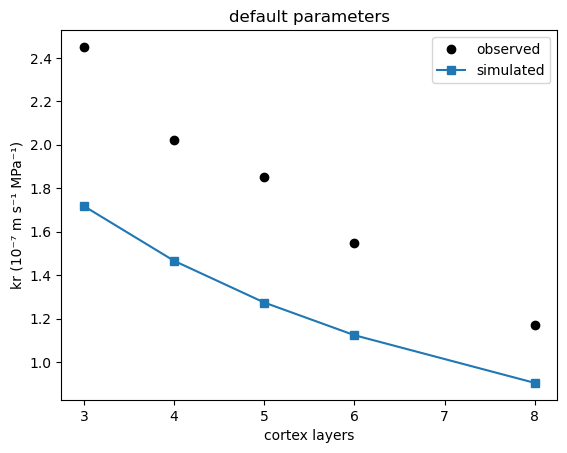

In [3]:
def compare(simulated, title):
    plt.plot(data["cortex_layers"], data["kr"] * 1e7, "o", color="k", label="observed")
    plt.plot(data["cortex_layers"], simulated * 1e7, "s-", label="simulated")
    plt.xlabel("cortex layers"); plt.ylabel("kr (10⁻⁷ m s⁻¹ MPa⁻¹)"); plt.title(title); plt.legend()


def relative_rmse(simulated):
    return float(np.sqrt(np.mean(((simulated - data["kr"]) / data["kr"]) ** 2)))


compare(with_defaults, "default parameters")
print(f"error with the defaults: {100 * relative_rmse(with_defaults):.0f} %")

The model reproduces the trend: more cortex layers make a longer path and a lower kr. But it underestimates every
root. The **relative root mean square error** sums up the difference in one number. It is computed on each root's
relative difference, so that it reads as a percentage.

## 4. Fit a parameter

The aquaporins (`kaqp`) drive kr most (tutorial 4). Fitting `kaqp` means finding the value that makes the error
smallest. `scipy.optimize.minimize_scalar` searches it between two bounds by running the model repeatedly:

In [4]:
from scipy.optimize import minimize_scalar

fit = minimize_scalar(lambda kaqp: relative_rmse(simulate_roots({"kaqp": kaqp})), bounds=(1e-4, 2e-3),
                      method="bounded", options={"xatol": 1e-6})
print(f"fitted kaqp = {fit.x:.2e} cm hPa-1 d-1 after {fit.nfev} evaluations; error {100 * fit.fun:.1f} %")
print("the value used to make the synthetic data: 8.0e-04")

fitted kaqp = 8.03e-04 cm hPa-1 d-1 after 9 evaluations; error 3.0 %
the value used to make the synthetic data: 8.0e-04


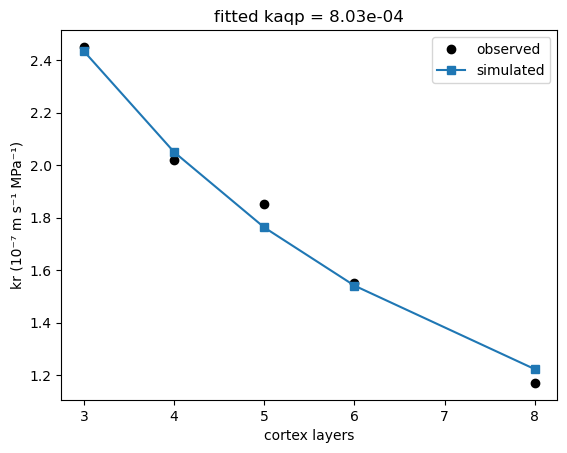

In [5]:
compare(simulate_roots({"kaqp": fit.x}), f"fitted kaqp = {fit.x:.2e}")

The fitted value is close to the true one. What remains of the error is the noise added to the data.

With real data, keep some roots out of the fit to check the model's predictions on them. Remember that other
parameters (the walls, the plasmodesmata) also act on kr: fitting one parameter attributes all the difference to it.
Measurements that separate the pathways help, for example kr with the aquaporins inhibited.

## Try it yourself

1. Fit `kw` instead of `kaqp`. Can it reach the same error? What does it tell about which parameter the data can
   identify?
2. Fit `kaqp_endo_factor` (the endodermis' aquaporins only) and compare the error with the fit of `kaqp`.
3. Prepare a CSV of your own roots (a measured anatomical trait, an observed kr) and compare them with MECHA.

**Next:** `06_along_a_root.ipynb`.